##### loading the dataset and required libraries

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             roc_auc_score)

In [2]:
data = pd.read_csv('credit_risk_dataset.csv')
data

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


##### data cleaning - checking for missing and duplicate values

In [3]:
data.isnull().sum()  ### checking for missing values

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [4]:
print(data.duplicated().sum())  ## checking for duplicate rows

165


In [5]:
data1 = data.drop_duplicates()  ## removing duplicate rows


##### Exploitary Data Analysis

In [6]:
data1.shape   ### number of rows and columns

(32416, 12)

In [7]:
data1.info()

<class 'pandas.DataFrame'>
Index: 32416 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32416 non-null  int64  
 1   person_income               32416 non-null  int64  
 2   person_home_ownership       32416 non-null  str    
 3   person_emp_length           31529 non-null  float64
 4   loan_intent                 32416 non-null  str    
 5   loan_grade                  32416 non-null  str    
 6   loan_amnt                   32416 non-null  int64  
 7   loan_int_rate               29321 non-null  float64
 8   loan_status                 32416 non-null  int64  
 9   loan_percent_income         32416 non-null  float64
 10  cb_person_default_on_file   32416 non-null  str    
 11  cb_person_cred_hist_length  32416 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.8 MB


In [8]:
data1.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32416.000000,3.241600e+04,31529.00000,32416.000000,29321.000000,32416.000000,32416.000000,32416.000000
mean,27.747008,6.609164e+04,4.79051,9593.845632,11.017265,0.218688,0.170250,5.811297
std,6.354100,6.201558e+04,4.14549,6322.730241,3.241680,0.413363,0.106812,4.059030
min,20.000000,4.000000e+03,0.00000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.854200e+04,2.00000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.00000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.921800e+04,7.00000,12250.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.00000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [9]:
data1.value_counts()

person_age  person_income  person_home_ownership  person_emp_length  loan_intent      loan_grade  loan_amnt  loan_int_rate  loan_status  loan_percent_income  cb_person_default_on_file  cb_person_cred_hist_length
22          59000          RENT                   123.0              PERSONAL         D           35000      16.02          1            0.59                 Y                          3                             1
21          9600           OWN                    5.0                EDUCATION        B           1000       11.14          0            0.10                 N                          2                             1
25          9600           MORTGAGE               1.0                MEDICAL          C           5500       12.87          1            0.57                 N                          3                             1
23          65500          RENT                   4.0                MEDICAL          C           35000      15.23          1            

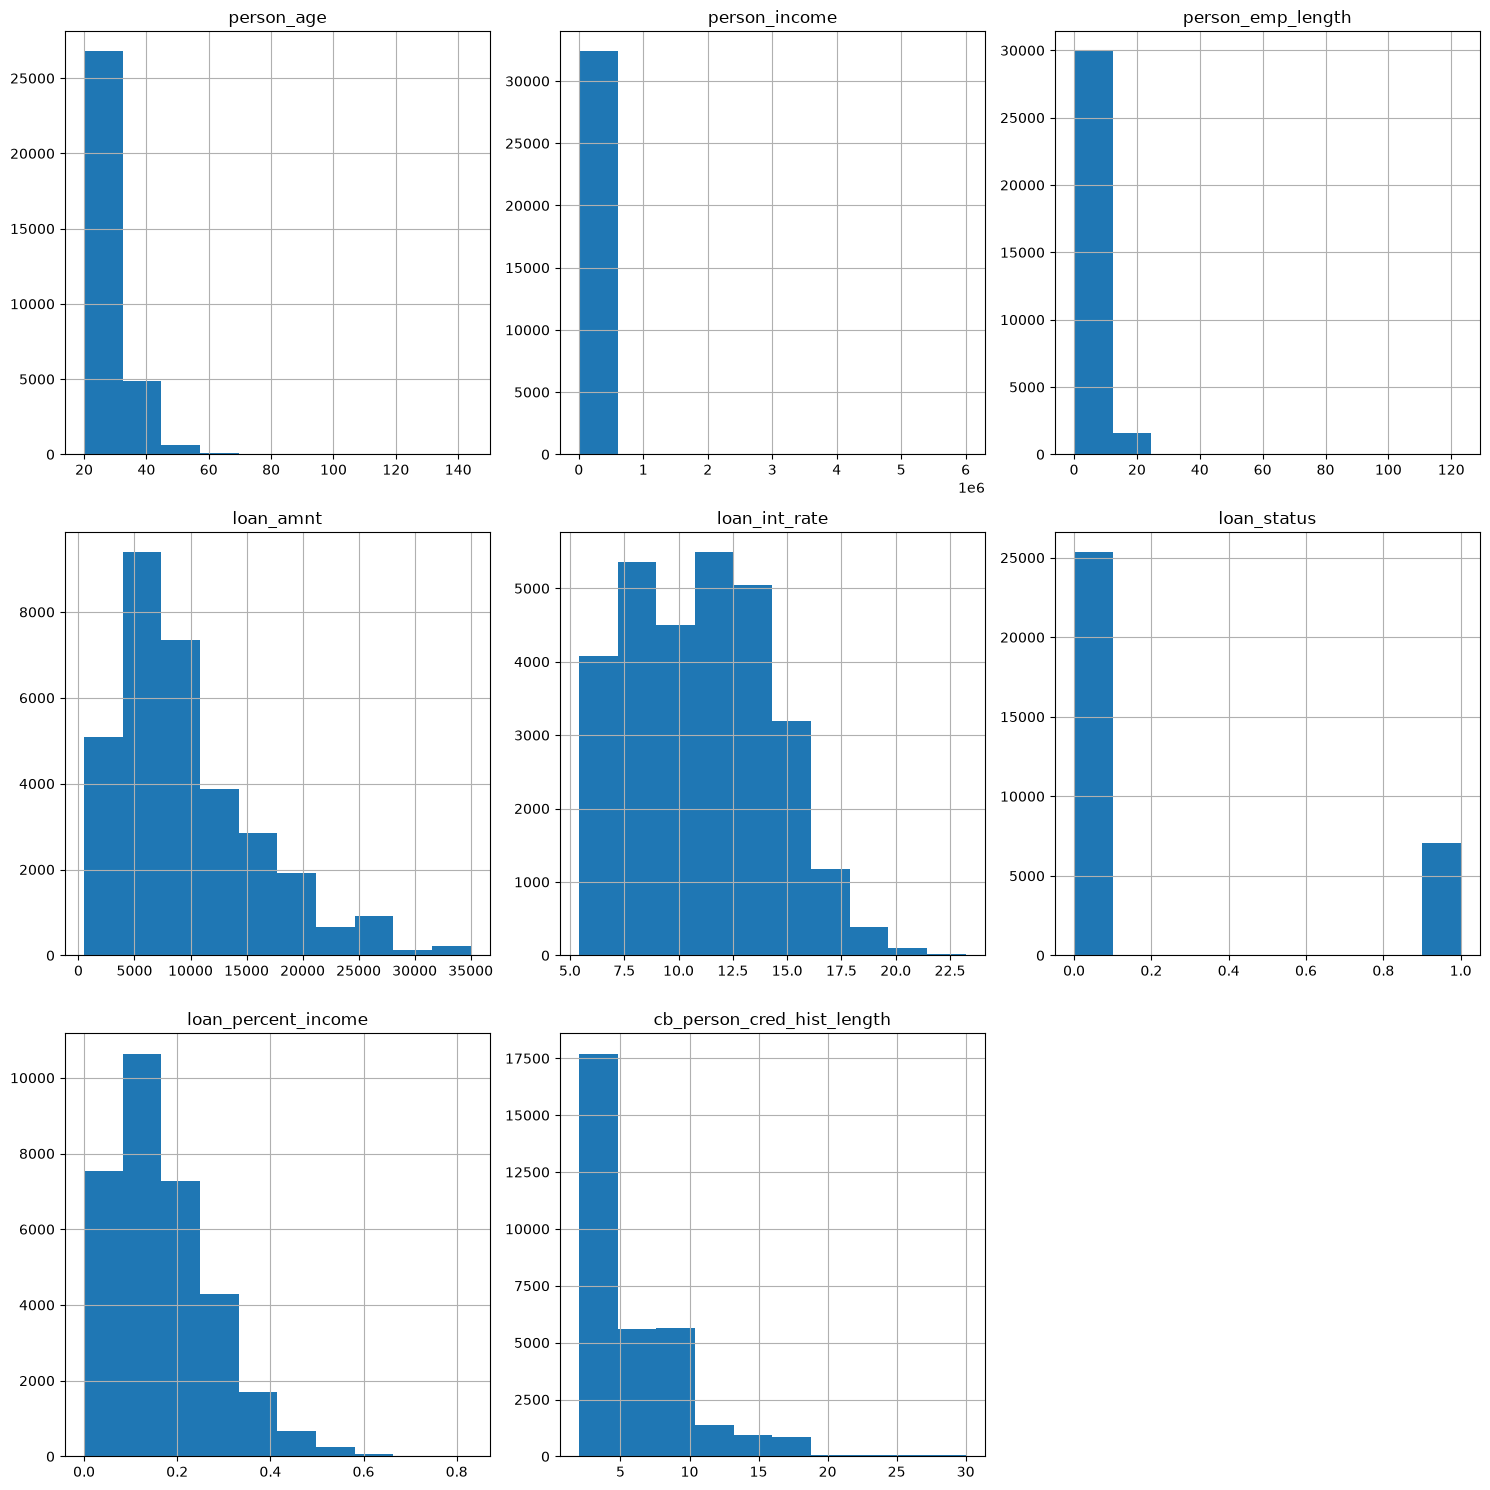

In [10]:
data1.hist(figsize=(15,15), bins=10)
plt.tight_layout()
plt.show()

In [11]:
data1['loan_status'].value_counts()  ### checking target class distribution

loan_status
0    25327
1     7089
Name: count, dtype: int64

##### Outlier Analysis

In [12]:
num_cols = data1.select_dtypes(include='number').columns### identifying numerical columns
num_cols

Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_cred_hist_length'],
      dtype='str')

In [13]:
num_cols = num_cols.drop(['loan_status'])  ## removing target sample from outlier analysis
num_cols

Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='str')

In [14]:
len(num_cols)

7

In [15]:
data2 = data1[num_cols]
data2

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length
0,22,59000,123.0,35000,16.02,0.59,3
1,21,9600,5.0,1000,11.14,0.10,2
2,25,9600,1.0,5500,12.87,0.57,3
3,23,65500,4.0,35000,15.23,0.53,2
4,24,54400,8.0,35000,14.27,0.55,4
...,...,...,...,...,...,...,...
32576,57,53000,1.0,5800,13.16,0.11,30
32577,54,120000,4.0,17625,7.49,0.15,19
32578,65,76000,3.0,35000,10.99,0.46,28
32579,56,150000,5.0,15000,11.48,0.10,26


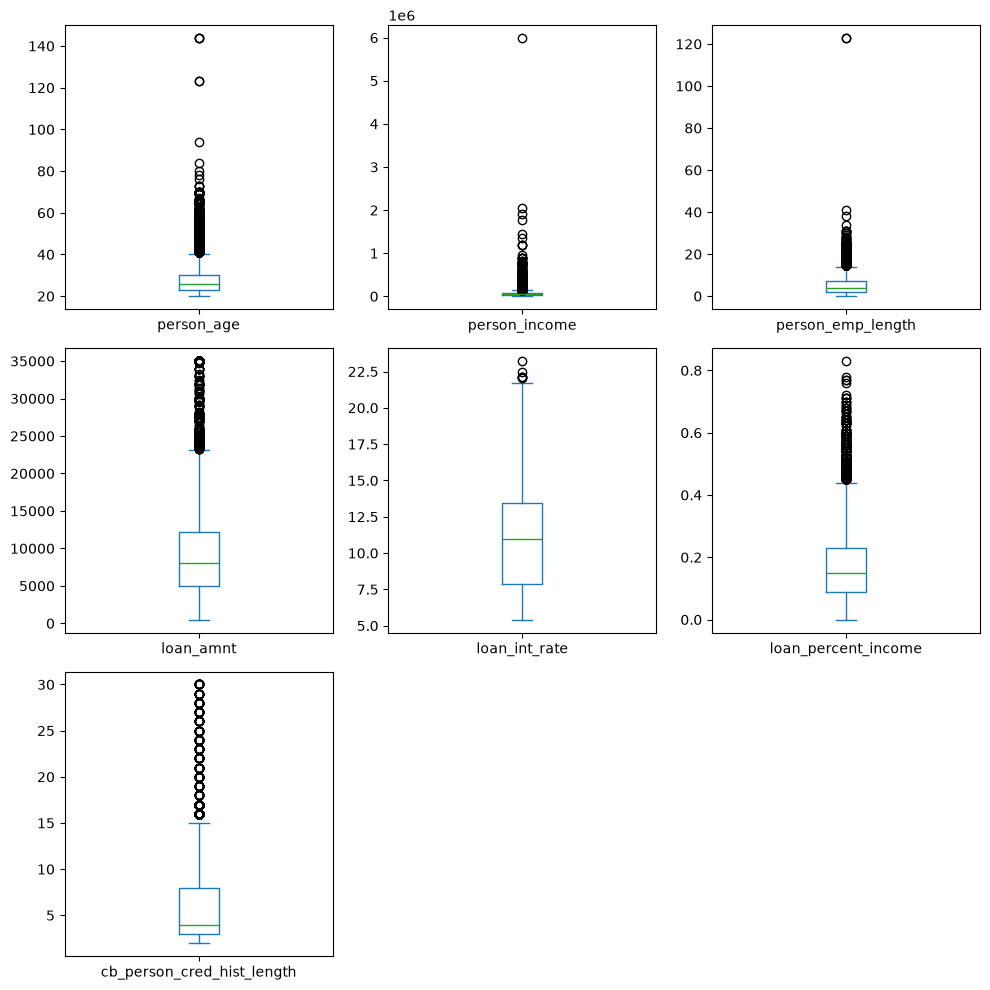

In [16]:
data2.plot(kind='box', subplots=True, layout=(3,3), figsize=(10,10))  ### boxplot
plt.tight_layout()
plt.show()

In [17]:
### outlier removal
for col in num_cols:
    Q1 = data1[col].quantile(0.25)
    Q3 = data1[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    data2 = data1[(data1[col] >= lower) & (data1[col] <= upper)]




In [18]:
cat_cols = data1.select_dtypes(include='object').columns  #### extracting string columns
cat_cols

C:\Users\Deekshit Gangadhar\AppData\Local\Temp\ipykernel_15712\4085450738.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = data1.select_dtypes(include='object').columns  #### extracting string columns


Index(['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file'],
      dtype='str')

##### Data Splitting

In [19]:
data2['loan_status'] = data1.loc[data2.index, 'loan_status']
x = data2.drop('loan_status', axis=1)
y = data2['loan_status']

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)


##### Handling Missing Values

In [20]:
# Handle missing values using training median
for col in ['person_emp_length', 'loan_int_rate']:
    median = x_train[col].median()
    x_train[col] = x_train[col].fillna(median)
    x_test[col] = x_test[col].fillna(median)
 

##### Categorical Data Analysis

In [21]:
data2.select_dtypes(include='object').columns  ### categorical columns

C:\Users\Deekshit Gangadhar\AppData\Local\Temp\ipykernel_15712\2093789737.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  data2.select_dtypes(include='object').columns  ### categorical columns


Index(['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file'],
      dtype='str')

In [22]:
data2.select_dtypes(include='object')

C:\Users\Deekshit Gangadhar\AppData\Local\Temp\ipykernel_15712\1372416088.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  data2.select_dtypes(include='object')


,person_home_ownership,loan_intent,loan_grade,cb_person_default_on_file
0,RENT,PERSONAL,D,Y
1,OWN,EDUCATION,B,N
2,MORTGAGE,MEDICAL,C,N
3,RENT,MEDICAL,C,N
4,RENT,MEDICAL,C,Y
...,...,...,...,...
32290,MORTGAGE,DEBTCONSOLIDATION,A,N
32292,MORTGAGE,DEBTCONSOLIDATION,A,N
32293,MORTGAGE,MEDICAL,B,N
32294,MORTGAGE,DEBTCONSOLIDATION,A,N


##### Categorical Encoding

In [23]:
### label encoding for loan grade 
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

x_train['loan_grade'] = le.fit_transform(x_train['loan_grade'])
x_test['loan_grade'] = le.transform(x_test['loan_grade'])

In [24]:
### one hot encoding for 'person_home_ownership', 'loan_intent', 'cb_person_default_on_file'
from sklearn.preprocessing import OneHotEncoder

cols = ['person_home_ownership', 'loan_intent', 'cb_person_default_on_file']

one = OneHotEncoder(sparse_output=False)

encoded = one.fit_transform(x_train[cols])
encoded_test = one.transform(x_test[cols])

encoded_cols = one.get_feature_names_out(cols)

x_train[encoded_cols] = encoded
x_test[encoded_cols] = encoded_test

x_train = x_train.drop(columns=cols)
x_test = x_test.drop(columns=cols)

In [25]:
x_train

,person_age,person_income,person_emp_length,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,person_home_ownership_MORTGAGE,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,cb_person_default_on_file_N,cb_person_default_on_file_Y
2616,21,40000,0.0,0,3000,10.99,0.07,3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
25560,28,86004,12.0,1,3000,9.99,0.03,5,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
26741,27,110000,4.0,0,2500,8.07,0.02,6,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
1790,21,23040,3.0,2,2000,13.11,0.09,2,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
8844,23,60000,6.0,0,10000,5.42,0.17,4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7960,22,54000,1.0,2,7000,13.47,0.13,2,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1402,24,42000,2.0,2,1000,13.16,0.02,2,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
11264,23,66500,0.0,1,22000,8.88,0.33,2,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
14414,25,105897,9.0,1,25000,11.36,0.24,3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [26]:
x_test

,person_age,person_income,person_emp_length,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,person_home_ownership_MORTGAGE,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,cb_person_default_on_file_N,cb_person_default_on_file_Y
21015,30,39000,13.0,2,3000,13.99,0.08,10,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
11305,25,73000,9.0,1,9000,11.86,0.12,4,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
16548,26,60000,10.0,0,12500,6.92,0.21,3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
5659,22,39696,4.0,1,14125,12.42,0.36,4,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
5118,26,43873,4.0,3,17500,16.32,0.40,3,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15278,22,128474,6.0,0,30000,7.29,0.23,2,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
15748,24,162000,8.0,2,16000,15.96,0.10,2,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4398,22,32000,3.0,3,4800,16.49,0.15,2,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
9752,25,64000,10.0,0,5000,7.29,0.08,2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [27]:
x_train.drop(columns=['person_home_ownership_OTHER','loan_intent_VENTURE','cb_person_default_on_file_N'])

,person_age,person_income,person_emp_length,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,person_home_ownership_MORTGAGE,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,cb_person_default_on_file_Y
2616,21,40000,0.0,0,3000,10.99,0.07,3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
25560,28,86004,12.0,1,3000,9.99,0.03,5,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
26741,27,110000,4.0,0,2500,8.07,0.02,6,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1790,21,23040,3.0,2,2000,13.11,0.09,2,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0
8844,23,60000,6.0,0,10000,5.42,0.17,4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7960,22,54000,1.0,2,7000,13.47,0.13,2,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1402,24,42000,2.0,2,1000,13.16,0.02,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
11264,23,66500,0.0,1,22000,8.88,0.33,2,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
14414,25,105897,9.0,1,25000,11.36,0.24,3,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [28]:
data2['loan_status'].value_counts()  ### there is class imbalance so we will use class weights
data2['loan_status'].value_counts(normalize=True)*100

loan_status
0    78.1245
1    21.8755
Name: proportion, dtype: float64

##### Data Scaling

In [29]:
num_cols = ['person_age', 'person_income', 'person_emp_length',
            'loan_amnt', 'loan_int_rate', 'loan_percent_income',
            'cb_person_cred_hist_length']

In [30]:
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()
x_train[num_cols] = ss.fit_transform(x_train[num_cols])
x_test[num_cols] = ss.transform(x_test[num_cols])

##### Model Training

##### logistic Regression

In [31]:
from sklearn.linear_model import LogisticRegression

log = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
log.fit(x_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [32]:
### model evaluation
y_pred1 = log.predict(x_test)
y_pred1

array([0, 0, 0, ..., 1, 0, 0], shape=(6256,))

In [33]:
y_test

21015    1
11305    0
16548    0
5659     1
5118     0
        ..
15278    0
15748    0
4398     1
9752     0
410      0
Name: loan_status, Length: 6256, dtype: int64

In [34]:
print("confusion matrix :\n", confusion_matrix(y_test,y_pred1))
print("accuracy\n", accuracy_score(y_test,y_pred1))
print("precision\n", precision_score(y_test,y_pred1))
print("recall\n", recall_score(y_test,y_pred1))
print("f1 score\n", f1_score(y_test,y_pred1))
print("roc auc\n", roc_auc_score(y_test,log.predict_proba(x_test)[:,1]))

confusion matrix :
 [[3863 1024]
 [ 297 1072]]
accuracy
 0.7888427109974424
precision
 0.5114503816793893
recall
 0.7830533235938641
f1 score
 0.6187590187590187
roc auc
 0.8682696433928327


In [35]:
### k fold validation
from sklearn.model_selection import StratifiedKFold, cross_val_score
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
result1 = cross_val_score(log, x_train, y_train, scoring='f1', cv=kfold, n_jobs=-1)
print(result1)
print(result1.mean())

[0.62334802 0.61682918 0.61002179 0.62545721 0.61824687]
0.6187806118584523


In [36]:
### hyperparametre tuning
from sklearn.model_selection import GridSearchCV

para_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'class_weight': ['balanced'],
    'solver': ['liblinear', 'lbfgs']
}

grid_search = GridSearchCV(
    LogisticRegression(max_iter=2000, random_state=42),
    para_grid, scoring='f1', cv=kfold, n_jobs=-1, verbose=1
)
grid_search.fit(x_train, y_train)
print("Best Parameters:", grid_search.best_params_)
print("Best CV F1 Score:", grid_search.best_score_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters: {'C': 10, 'class_weight': 'balanced', 'solver': 'liblinear'}
Best CV F1 Score: 0.6190494223993703


In [37]:
best_model = grid_search.best_estimator_
y_pred = best_model.predict(x_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print("accuracy:", accuracy_score(y_test, y_pred))
print("precision:", precision_score(y_test, y_pred))
print("recall:", recall_score(y_test, y_pred))
print("f1 score:", f1_score(y_test, y_pred))
print("roc auc:", roc_auc_score(y_test, best_model.predict_proba(x_test)[:,1]))

Confusion Matrix:
[[3864 1023]
 [ 297 1072]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.79      0.85      4887
           1       0.51      0.78      0.62      1369

    accuracy                           0.79      6256
   macro avg       0.72      0.79      0.74      6256
weighted avg       0.84      0.79      0.80      6256

accuracy: 0.789002557544757
precision: 0.5116945107398568
recall: 0.7830533235938641
f1 score: 0.6189376443418014
roc auc: 0.8682334716379813


##### Decision Tree Classifier

In [38]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score

dt_model = DecisionTreeClassifier(random_state=42, class_weight='balanced')
dt_model.fit(x_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_f

In [39]:
### ModelEvaluation
y_pred_dt = dt_model.predict(x_test)
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1 Score:", f1_score(y_test, y_pred_dt))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))

Accuracy: 0.899616368286445
Precision: 0.7808946171341926
Recall: 0.7523739956172388
F1 Score: 0.7663690476190477
Confusion Matrix:
 [[4598  289]
 [ 339 1030]]


In [40]:
### KFold cross validation
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(dt_model, x_train, y_train, cv=kfold, scoring='f1', n_jobs=-1)
print("F1 Scores:", scores)
print("Average F1 Score:", scores.mean())

F1 Scores: [0.75492442 0.76516188 0.74       0.75426009 0.7450805 ]
Average F1 Score: 0.7518853770453777


In [41]:
### Hyperparametre Tuning
para_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [5, 10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
grid_search_dt = GridSearchCV(dt_model, para_grid, scoring='f1', cv=kfold, n_jobs=-1, verbose=1)
grid_search_dt.fit(x_train, y_train)
print("Best Parameters:", grid_search_dt.best_params_)
print("Best CV F1 Score:", grid_search_dt.best_score_)

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best Parameters: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV F1 Score: 0.7975876090257904


In [42]:
model_dt = grid_search_dt.best_estimator_
y_pred_dt = model_dt.predict(x_test)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1 Score:", f1_score(y_test, y_pred_dt))

Confusion Matrix:
[[4777  110]
 [ 370  999]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.98      0.95      4887
           1       0.90      0.73      0.81      1369

    accuracy                           0.92      6256
   macro avg       0.91      0.85      0.88      6256
weighted avg       0.92      0.92      0.92      6256

Accuracy: 0.9232736572890026
Precision: 0.9008115419296664
Recall: 0.7297297297297297
F1 Score: 0.8062953995157385


##### Random Forest Classifier

In [43]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_jobs=-1, class_weight='balanced', random_state=42)
rf_model.fit(x_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [44]:
### Model Evaluation
y_pred_rf = rf_model.predict(x_test)
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

Accuracy: 0.9293478260869565
Precision: 0.9209809264305178
Recall: 0.7406866325785245
F1 Score: 0.8210526315789474
Confusion Matrix:
 [[4800   87]
 [ 355 1014]]


In [45]:
### KFold cross validation
rf_scores = cross_val_score(rf_model, x_train, y_train, cv=kfold, scoring='f1', n_jobs=-1)
print("F1 Scores:", rf_scores)
print("Average F1 Score:", rf_scores.mean())

F1 Scores: [0.82020202 0.81912272 0.81119593 0.82388664 0.81771894]
Average F1 Score: 0.8184252500240348


In [46]:
### Hyperparametre Tuning
param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt']
}
grid_search_rf = GridSearchCV(rf_model, param_grid_rf, scoring='f1', cv=kfold, n_jobs=-1, verbose=1)
grid_search_rf.fit(x_train, y_train)
print("Best Parameters:", grid_search_rf.best_params_)
print("Best CV F1 Score:", grid_search_rf.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Best CV F1 Score: 0.8190930502764606


In [47]:
model_rf = grid_search_rf.best_estimator_
y_pred_rf = model_rf.predict(x_test)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))

Confusion Matrix:
[[4792   95]
 [ 356 1013]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.98      0.96      4887
           1       0.91      0.74      0.82      1369

    accuracy                           0.93      6256
   macro avg       0.92      0.86      0.89      6256
weighted avg       0.93      0.93      0.93      6256

Accuracy: 0.9279092071611253
Precision: 0.9142599277978339
Recall: 0.7399561723886048
F1 Score: 0.8179249091643117


##### XGBoost model

In [48]:
!pip install xgboost


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [49]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

In [50]:
xgb_model = XGBClassifier(
    objective='binary:logistic', eval_metric='logloss',
    random_state=42, tree_method='hist', n_jobs=1,
)
xgb_model.fit(x_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [51]:
### Model Evaluation
y_pred_xgb = xgb_model.predict(x_test)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))
print("F1 Score:", f1_score(y_test, y_pred_xgb))

Confusion Matrix:
[[4837   50]
 [ 354 1015]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      4887
           1       0.95      0.74      0.83      1369

    accuracy                           0.94      6256
   macro avg       0.94      0.87      0.90      6256
weighted avg       0.94      0.94      0.93      6256

Accuracy: 0.9354219948849105
Precision: 0.9530516431924883
Recall: 0.7414170927684441
F1 Score: 0.8340180772391126


In [52]:
#### KFold cross validation
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores_xgb = cross_val_score(xgb_model, x_train, y_train, cv=kfold, scoring='f1', n_jobs=1)
print(cv_scores_xgb)
print("Mean F1 Score:", cv_scores_xgb.mean())

[0.83778234 0.83893986 0.82619907 0.82744283 0.83677686]
Mean F1 Score: 0.8334281913568601


In [53]:
#### hyperparametre tuning
param_grid_xgb = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5],
    'learning_rate': [0.05, 0.1],
}
grid_search_xgb = GridSearchCV(
    xgb_model, param_grid_xgb, scoring='f1', cv=kfold, n_jobs=-1, verbose=2
)
grid_search_xgb.fit(x_train, y_train)
print("Best Parameters:", grid_search_xgb.best_params_)
print("Best CV F1 Score:", grid_search_xgb.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}
Best CV F1 Score: 0.8310183990352961


In [54]:
model_xgb = grid_search_xgb.best_estimator_
y_pred_xgb = model_xgb.predict(x_test)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))
print("F1 Score:", f1_score(y_test, y_pred_xgb))


Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      4887
           1       0.97      0.73      0.84      1369

    accuracy                           0.94      6256
   macro avg       0.95      0.86      0.90      6256
weighted avg       0.94      0.94      0.93      6256

Confusion Matrix:
[[4858   29]
 [ 364 1005]]
Accuracy: 0.9371803069053708
Precision: 0.971953578336557
Recall: 0.7341124908692477
F1 Score: 0.83645443196005


##### SVM Model

In [55]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    random_state=42, max_iter=10000, class_weight='balanced'
)
svm_model.fit(x_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forthe dual coordinate descent (if ``dual=True``). When ``dual=False`` theunderlying implementation of :class:`LinearSVC` is not random and``random_state`` has no effect on the results.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_iter max_iter: int, default=1000The maximum number of iterations to be run.",10000
,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w

In [56]:
### Model Evaluation
y_pred_svm = svm_model.predict(x_test)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm))
print("Recall:", recall_score(y_test, y_pred_svm))
print("F1 Score:", f1_score(y_test, y_pred_svm))
print("ROC-AUC:", roc_auc_score(y_test, svm_model.decision_function(x_test)))

Confusion Matrix:
[[3871 1016]
 [ 300 1069]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.79      0.85      4887
           1       0.51      0.78      0.62      1369

    accuracy                           0.79      6256
   macro avg       0.72      0.79      0.74      6256
weighted avg       0.84      0.79      0.80      6256

Accuracy: 0.7896419437340153
Precision: 0.5127098321342926
Recall: 0.7808619430241052
F1 Score: 0.6189924724956573
ROC-AUC: 0.8682789105366379


In [57]:
### KFold cross validation
cv_scores_svm = cross_val_score(svm_model, x_train, y_train, cv=kfold, scoring='f1', n_jobs=-1)
print("Fold Scores:", cv_scores_svm)
print("Mean F1 Score:", cv_scores_svm.mean())

Fold Scores: [0.62477031 0.61839247 0.61100984 0.62706271 0.62096195]
Mean F1 Score: 0.6204394552776631


In [58]:
#### hyperparametre tuning
param_grid_svm = {'C': [0.01, 0.1, 1, 10]}
grid_search_svm = GridSearchCV(
    svm_model, param_grid_svm, cv=kfold, scoring='f1', n_jobs=-1, verbose=2
)
grid_search_svm.fit(x_train, y_train)
print("Best Parameters:", grid_search_svm.best_params_)
print("Best CV F1 Score:", grid_search_svm.best_score_)

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best Parameters: {'C': 10}
Best CV F1 Score: 0.6205736706926142


In [59]:
model_svm = grid_search_svm.best_estimator_
y_pred_svm = model_svm.predict(x_test)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm))
print("Recall:", recall_score(y_test, y_pred_svm))
print("F1 Score:", f1_score(y_test, y_pred_svm))

Confusion Matrix:
[[3871 1016]
 [ 300 1069]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.79      0.85      4887
           1       0.51      0.78      0.62      1369

    accuracy                           0.79      6256
   macro avg       0.72      0.79      0.74      6256
weighted avg       0.84      0.79      0.80      6256

Accuracy: 0.7896419437340153
Precision: 0.5127098321342926
Recall: 0.7808619430241052
F1 Score: 0.6189924724956573


##### Model Comparison

In [60]:
models = {
    'Logistic Regression': best_model,
    'Decision Tree': model_dt,
    'Random Forest': model_rf,
    'XGBoost': model_xgb,
    'SVM': model_svm
}

results = []
for name, model in models.items():
    y_pred_model = model.predict(x_test)
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred_model),
        'Precision': precision_score(y_test, y_pred_model),
        'Recall': recall_score(y_test, y_pred_model),
        'F1 Score': f1_score(y_test, y_pred_model)
    })

results_df = pd.DataFrame(results)
results_df.sort_values(by='F1 Score', ascending=False)

,Model,Accuracy,Precision,Recall,F1 Score
3,XGBoost,0.937180,0.971954,0.734112,0.836454
2,Random Forest,0.927909,0.914260,0.739956,0.817925
1,Decision Tree,0.923274,0.900812,0.729730,0.806295
4,SVM,0.789642,0.512710,0.780862,0.618992
0,Logistic Regression,0.789003,0.511695,0.783053,0.618938


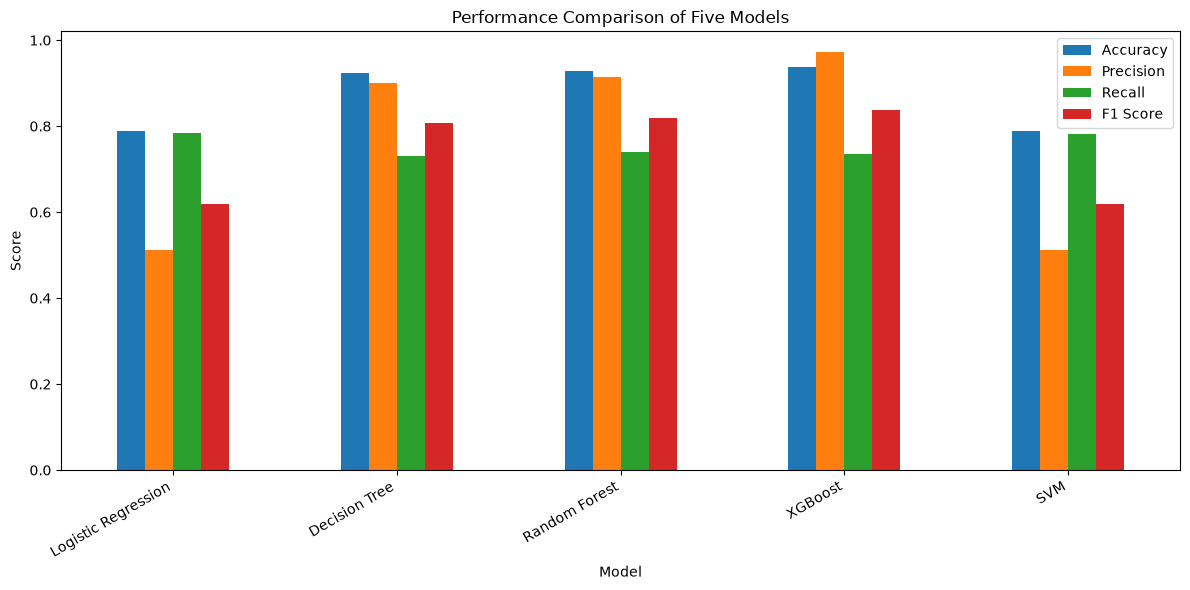

In [61]:
results_df.set_index('Model').plot(kind='bar', figsize=(12,6))
plt.title("Performance Comparison of Five Models")
plt.ylabel("Score")
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

In [62]:
### prediction agreement matrix

predictions = pd.DataFrame({
    name: model.predict(x_test)
    for name, model in models.items()
})

agreement_matrix = pd.DataFrame(index=predictions.columns, columns=predictions.columns, dtype=float)

for model1 in predictions.columns:
    for model2 in predictions.columns:
        agreement_matrix.loc[model1, model2] = (
            predictions[model1] == predictions[model2]
        ).mean()

agreement_matrix

,Logistic Regression,Decision Tree,Random Forest,XGBoost,SVM
Logistic Regression,1.000000,0.806905,0.808344,0.804188,0.996803
Decision Tree,0.806905,1.000000,0.969150,0.973625,0.807864
Random Forest,0.808344,0.969150,1.000000,0.977941,0.809623
XGBoost,0.804188,0.973625,0.977941,1.000000,0.805467
SVM,0.996803,0.807864,0.809623,0.805467,1.000000


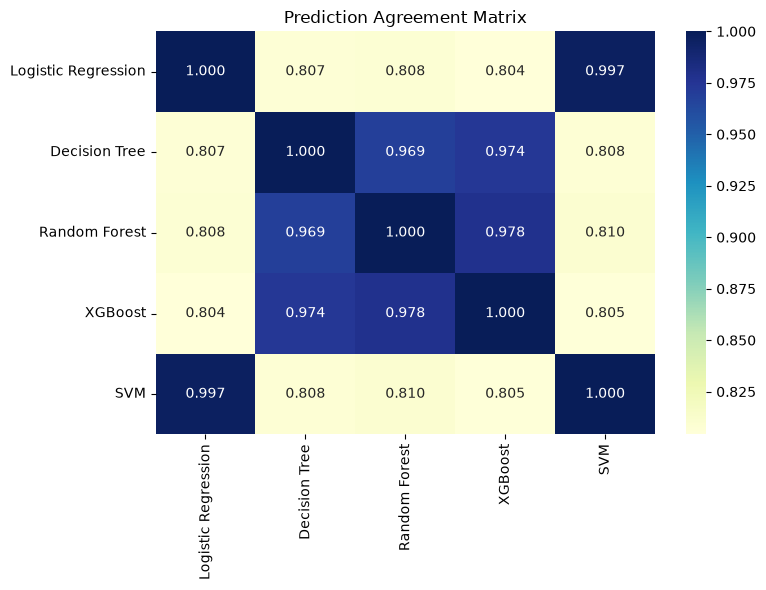

In [63]:
plt.figure(figsize=(8,6))
sns.heatmap(agreement_matrix, annot=True, fmt='.3f', cmap='YlGnBu')
plt.title("Prediction Agreement Matrix")
plt.tight_layout()
plt.show()

In [67]:
### final model using soft voting classifier
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

voting_clf = VotingClassifier(
    estimators=[
        ('lr', log),
        ('dt', dt_model),
        ('rf', rf_model),
        ('xgb', xgb_model)
    ],
    voting='soft',
    n_jobs=-1
)
voting_clf.fit(x_train, y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('lr', ...), ('dt', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'soft'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",-1
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[LogisticRegre...ndom_state=42), DecisionTreeC...ndom_state=42), RandomForestC...ndom_state=42), XGBClassifier...ree=None, ...)]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[<U30](20,)","['person_age','person_income','person_emp_length',..., 'loan_intent_VENTURE','cb_person_default_on_file_N', 'cb_person_default_on_file_Y']"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()


In [68]:
### model evaluation
y_pred = voting_clf.predict(x_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))

print("Recall:", recall_score(y_test, y_pred))

print("F1 Score:", f1_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.9269501278772379
Precision: 0.9021164021164021
Recall: 0.7472607742878014
F1 Score: 0.8174190970834998

Confusion Matrix:
[[4776  111]
 [ 346 1023]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.98      0.95      4887
           1       0.90      0.75      0.82      1369

    accuracy                           0.93      6256
   macro avg       0.92      0.86      0.89      6256
weighted avg       0.93      0.93      0.92      6256



In [70]:
### For Local Deployment
import joblib

# Save trained Voting Classifier
joblib.dump(voting_clf, 'credit_risk_model.pkl')

# Save fitted scaler
joblib.dump(ss, 'scaler.pkl')

# Save fitted encoder
joblib.dump(one, 'encoder.pkl')

print("All files saved successfully!")

All files saved successfully!
